### Comparison between SteadierCom and experimental results

In [2]:
import pandas as pd
import numpy as np
import json
import csv
import warnings
from os import listdir
from collections import defaultdict

import matplotlib.pyplot as plt
import seaborn as sns

import scipy as sp
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix,recall_score,precision_score,classification_report

import sys

sys.path.append("../functions/")

from compare_exp_sim import prepare_exp_met_venturelli,prepare_sim_met_venturelli,combine_exp_sim_met,scoring_met,plot_radar_chart

In [3]:
%load_ext autoreload
%autoreload 2

#### Mapping names to seed ids (seem to have a good overlap)

In [4]:
with open("../data/Venturelli2018/generated/metid2metname.json") as file:
    metid2metname = json.load(file)
    
with open("../data/Venturelli2018/generated/metname2metanetx.json") as file:
    metname2metanetx = json.load(file)
    
with open("../data/Venturelli2018/generated/metname_groups.json") as file:
    metname_groups = json.load(file)

with open("../data/Venturelli2018/generated/metname2group.json") as file:
    metname2group = json.load(file)

with open("../data/Venturelli2018/generated/metid2group.json") as file:
    metid2group = json.load(file)
    


In [5]:
len(set(metname2metanetx.keys())-set(metid2metname.values()))

33

**Metabolomics**

In [6]:
dataset4 = pd.read_excel("../data/Venturelli2018/msb178157-sup-0005-datasetev4.xlsx",sheet_name="Dataset EV4",index_col=0)
signal_exp = prepare_exp_met_venturelli(dataset4,metname_groups,metname2group)

**Load steadiercom results**

In [7]:
dfs = []
for file in listdir("../output/Venturelli2018/results_steadiercom/results_abundance/"):
    if file.endswith(".tsv") and (not file.endswith("growth.tsv")):
    
        df = pd.read_csv("../output/Venturelli2018/results_steadiercom/results_abundance/"+file,sep="\t")
        dfs.append(df)
steadiercom_abundance = pd.concat(dfs)

dfs = []
for file in listdir("../output/Venturelli2018/results_steadiercom/results_growth/"):
    if file.endswith(".tsv") and (not file.endswith("abundance.tsv")):
        df = pd.read_csv("../output/Venturelli2018/results_steadiercom/results_growth/"+file,sep="\t")
        dfs.append(df)
steadiercom_growth = pd.concat(dfs)

dfs = []
for file in listdir("../output/Venturelli2018/results_steadiercom/results_growth_abundance/"):
    if file.endswith(".tsv"):
        df = pd.read_csv("../output/Venturelli2018/results_steadiercom/results_growth_abundance/"+file,sep="\t")
        dfs.append(df)
steadiercom_growth_abundance = pd.concat(dfs)

**Load smetana results**

In [8]:
smetana = pd.read_csv("../output/Venturelli2018/smetana/no_coupling_detailed.tsv",sep="\t")

**Load steadycom results**

In [9]:
steadycom_fixed_abundance = pd.read_csv("../output/Venturelli2018/steadycom/cross_feeding_fixed_abundance.tsv",sep="\t")
steadycom = pd.read_csv("../output/Venturelli2018/steadycom/cross_feeding.tsv",sep="\t")

steadycom.donor = steadycom.donor.map(lambda x: x.replace("M_","") if isinstance(x,str) else x)
steadycom.receiver = steadycom.receiver.map(lambda x: x.replace("M_","") if isinstance(x,str) else x)

steadycom_fixed_abundance.donor = steadycom_fixed_abundance.donor.map(lambda x: x.replace("M_","") if isinstance(x,str) else x)
steadycom_fixed_abundance.receiver = steadycom_fixed_abundance.receiver.map(lambda x: x.replace("M_","") if isinstance(x,str) else x)

**Process data - add met_group to columns**

In [10]:

steadiercom_dict = {
    "SteadierCom - fixed growth":steadiercom_growth,
    "SteadierCom - fixed growth & abundance":steadiercom_growth_abundance,
    "SteadierCom - fixed abundance":steadiercom_abundance
}

steadycom_dict = {
    "SteadyCom - Nothing fixed":steadycom,
    "SteadyCom - Fixed  abundance":steadycom_fixed_abundance
}

smetana_dict = {"Smetana":smetana}



simulation_dict = {"receiver" : {"steadiercom": {key:prepare_sim_met_venturelli(simulated_results=value,
                                                           metid2group=metid2group,
                                                           receiver_or_donor="receiver") 
                                          for key, value in steadiercom_dict.items()},
                               "steadycom":{key:prepare_sim_met_venturelli(simulated_results=value,
                                                                         metid2group=metid2group,
                                                                         receiver_or_donor="receiver") 
                                          for key, value in steadycom_dict.items()},
                                "smetana":{key:prepare_sim_met_venturelli(simulated_results=value,
                                                                       metid2group=metid2group,
                                                                       receiver_or_donor="receiver") 
                                          for key, value in smetana_dict.items()}
                                  },
                     "donor": {"steadiercom": {key:prepare_sim_met_venturelli(simulated_results=value,
                                                                               metid2group=metid2group,
                                                                               receiver_or_donor="donor") 
                                                for key, value in steadiercom_dict.items()},
                                   "steadycom":{key:prepare_sim_met_venturelli(simulated_results=value,
                                                                             metid2group=metid2group,
                                                                             receiver_or_donor="donor") 
                                              for key, value in steadycom_dict.items()},
                                    "smetana":{key:prepare_sim_met_venturelli(simulated_results=value,
                                                                           metid2group=metid2group,
                                                                           receiver_or_donor="donor") 
                                            for key, value in smetana_dict.items()}
                                  }
                    }

In [11]:

def plot_scatter_plots(simulation_dict,simulation_method="steadiercom",receiver_or_donor="receiver",agg_method="sum",metric="frequency"):
    # Process simulated result
    collected_result = defaultdict(dict)
    for receiver_or_donor in ["donor","receiver"]:
        for name, simulated_res in simulation_dict[receiver_or_donor][simulation_method].items():

            exp_sim_combined = combine_exp_sim_met(
                simulated_res,
                signal_exp,
                metric=metric,
                agg_method=agg_method,
                receiver_or_donor=receiver_or_donor,
                met_column="met_group"
            ).fillna(0)

            collected_result[name][receiver_or_donor] = exp_sim_combined


    # Plot results    
    fig, axs = plt.subplots(2,3,figsize=(15,10))

    i = 0
    for name, subdict in collected_result.items():
        j = 0
        
        for receiver_or_donor,color in {"receiver":"tab:blue","donor":"tab:orange"}.items():
            ax = axs[j][i]

            merged = subdict[receiver_or_donor]
            sns.scatterplot(ax=ax,x="experimental", y="simulated", data=merged,alpha=0.5,color=color)
            
            if receiver_or_donor=="receiver":
                ax.set_title(f"{name}")

            ax.set_ylabel(f"Simulated - {agg_method} of {metric}")
            ax.set_xlabel(f"Experimental - log2 conc. change")
            if metric!="frequency":
                ax.set_yscale('log')

            ax.axvspan(-1, 1, alpha=0.2, color='grey')

            r, p = sp.stats.spearmanr(subdict[receiver_or_donor])
            plt.text(.1, .75, "Spearman's \n r={:.2f}, p-value={:.4f}".format(r,p), transform=ax.transAxes)
            j+=1

        i +=1
        
    fig.text(0.01, 0.70, "Receivers", va='center', ha='left', fontsize=12)
    
    fig.text(0.01, 0.30, "Donors", va='center', ha='left', fontsize=12)
    return fig,axs

## Scatterplots


Seeing if there is a relationship between simulated and experimental results

### NOTE
- We expect a **negative trend** for receiving rate/frequency with change in concentration. 
- We expect a **positive trend** for receiving rate/frequency with change in concentration. 

#### Receivers - SteadierCom - scatterplot - frequency

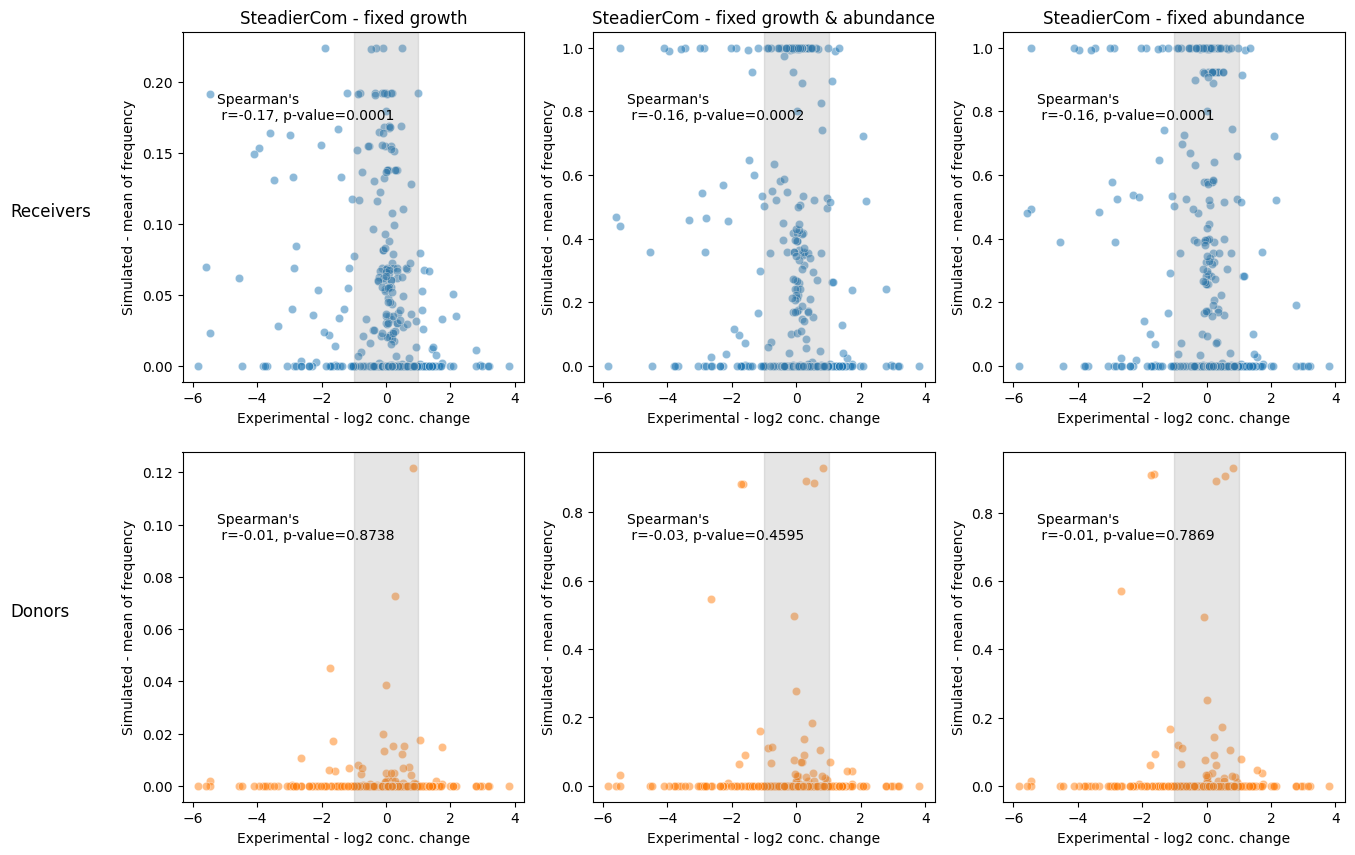

In [12]:
simulation_method="steadiercom"
receiver_or_donor="receiver"
agg_method ="mean"
metric = "frequency"
fig,axs = plot_scatter_plots(simulation_dict,
                   simulation_method=simulation_method,
                   receiver_or_donor=receiver_or_donor,
                   agg_method=agg_method,
                   metric=metric)


#### Receivers - SteadierCom - scatterplot - rate

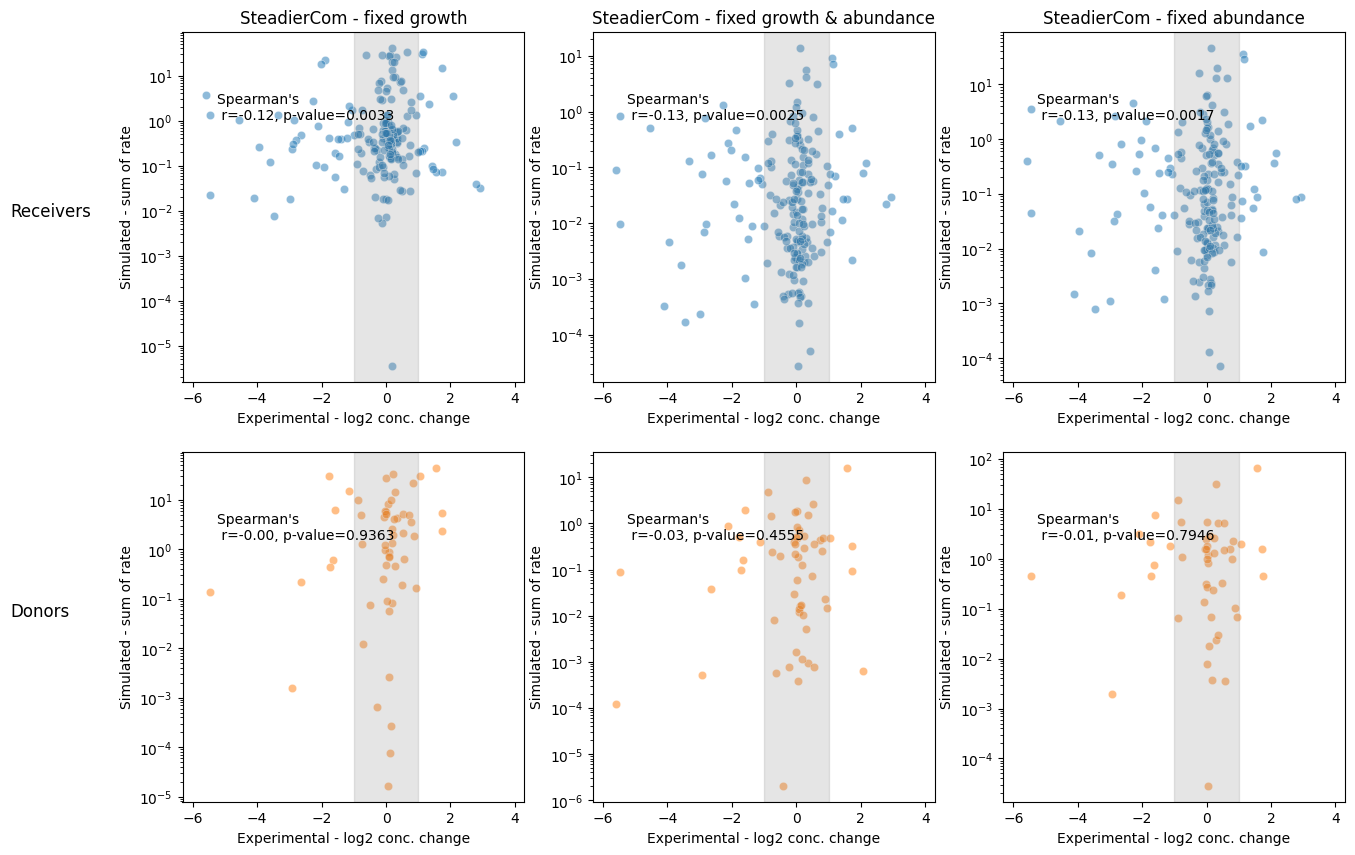

In [13]:
simulation_method="steadiercom"
receiver_or_donor="receiver"
agg_method ="sum"
metric = "rate"

fig,axs = plot_scatter_plots(simulation_dict,
                   simulation_method=simulation_method,
                   receiver_or_donor=receiver_or_donor,
                   agg_method=agg_method,
                   metric=metric)

#### Receivers - SteadierCom - scatterplot - mass_rate

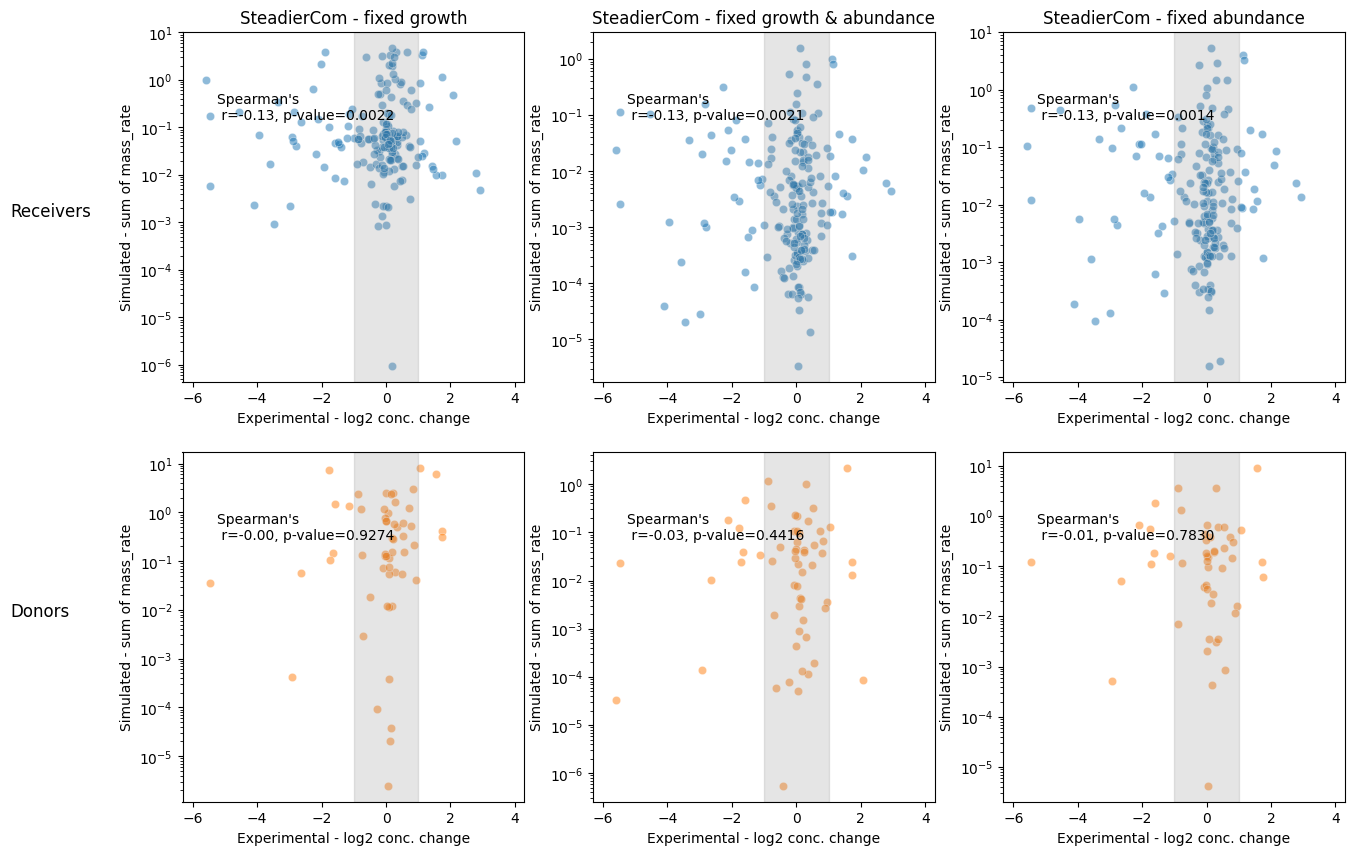

In [14]:
simulation_method="steadiercom"
receiver_or_donor="receiver"
agg_method ="sum"
metric = "mass_rate"

fig,axs = plot_scatter_plots(simulation_dict,
                   simulation_method=simulation_method,
                   receiver_or_donor=receiver_or_donor,
                   agg_method=agg_method,
                   metric=metric)

#### Receivers - SteadyCom - scatterplot

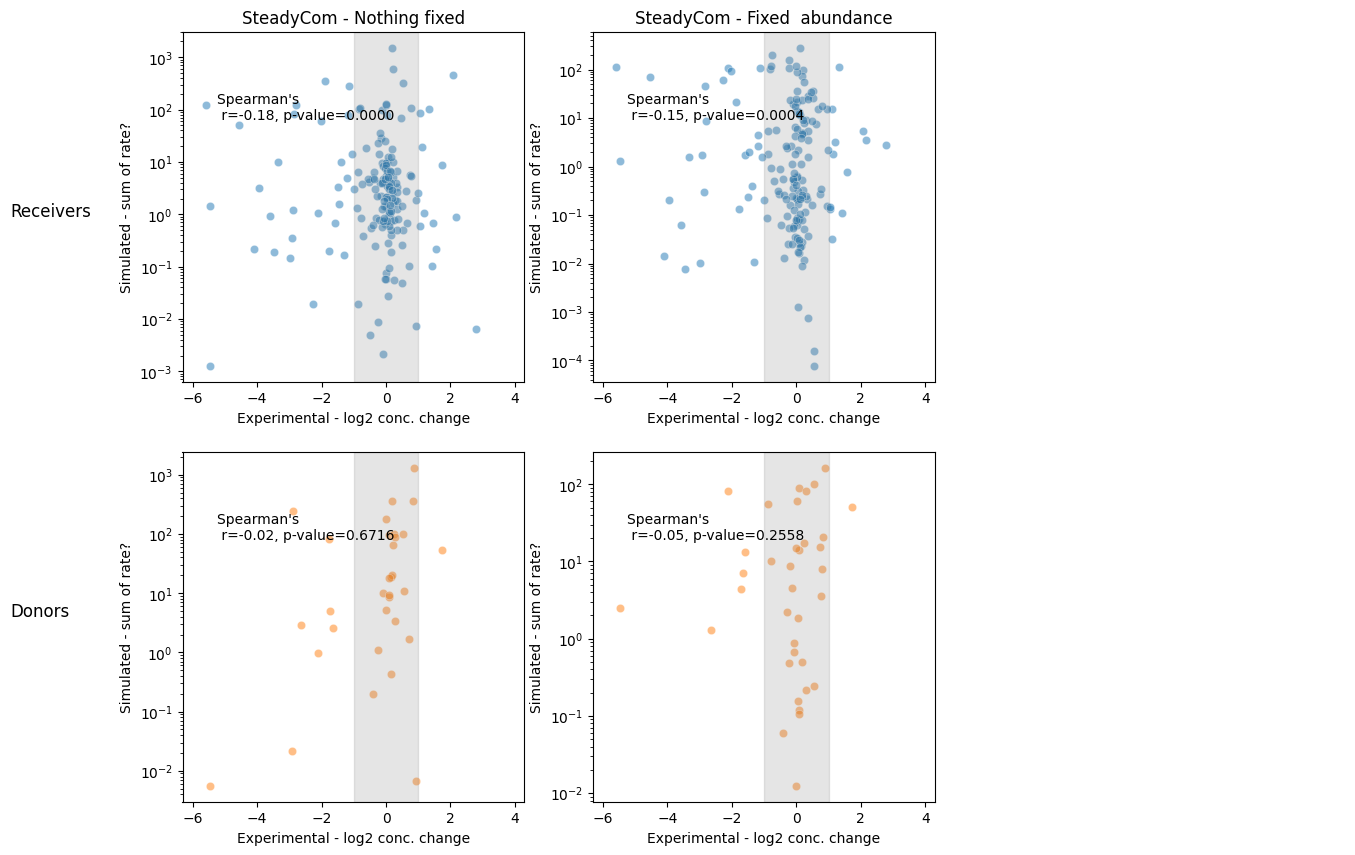

In [19]:

simulation_method="steadycom"
receiver_or_donor="receiver"
agg_method ="sum"
metric = "rate?"

fig,axs = plot_scatter_plots(simulation_dict,
                   simulation_method=simulation_method,
                   receiver_or_donor=receiver_or_donor,
                   agg_method=agg_method,
                   metric=metric)
axs[0][-1].set_axis_off()
axs[1][-1].set_axis_off()

## Confusion matrices

#### Receiver - SteadierCom and SteadyCom - rate

In [25]:
def plot_confusion_matrix_venturelli(simulation_dict,signal_exp,receiver_or_donor="receiver",steadycom_or_smetana="steadycom"):
    if steadycom_or_smetana=="steadycom":
        cf_sim_data_dict = {**{key:(value,"rate") for key,value in simulation_dict[receiver_or_donor]["steadiercom"].items()},
                            **{key:(value,"rate?") for key,value in simulation_dict[receiver_or_donor]["steadycom"].items()}} 
        fig,axs=plt.subplots(2,3,figsize=(15,10))
        axs_flat = axs.flatten()
        
        agg_method="sum"

    elif steadycom_or_smetana=="smetana":
        cf_sim_data_dict = {**{key:(value,"frequency") for key,value in simulation_dict[receiver_or_donor]["steadiercom"].items()},
                            **{key:(value,"mus") for key,value in simulation_dict[receiver_or_donor]["smetana"].items()}} 
    
        fig,axs=plt.subplots(2,2,figsize=(10,10))
        axs_flat = axs.flatten()
        
        agg_method="mean"
    else:
        raise Exception("Choose either 'steadycom' or 'smetana' for 'steadycom_or_smetana'")

        
    if receiver_or_donor=="receiver":
        exp_condition_str = "< -1"
        
        sim_thresh_freq = 0.1
        sim_thresh_rate = 1e-4
    elif receiver_or_donor=="donor":
        exp_condition_str = "> 1"   
        sim_thresh_freq = 0.01
        sim_thresh_rate = 1e-5
    # start plot

    i = 0

    for name,(sim_df,metric) in cf_sim_data_dict.items():
        exp_sim_combined = combine_exp_sim_met(sim_df,
                                       signal_exp,
                                       agg_method=agg_method,
                                       metric=metric,   
                                       receiver_or_donor=receiver_or_donor,
                                       met_column="met_group")

        if receiver_or_donor=="receiver":
            exp_sim_combined.experimental = exp_sim_combined.experimental<-1
        elif receiver_or_donor=="donor":
            exp_sim_combined.experimental = exp_sim_combined.experimental>1
        else:
            raise Exception()
        
        if steadycom_or_smetana=="steadycom":
            exp_sim_combined.simulated = exp_sim_combined.simulated>sim_thresh_rate            
        elif steadycom_or_smetana=="smetana":
            exp_sim_combined.simulated = exp_sim_combined.simulated>sim_thresh_freq
            
        cf_matrix = confusion_matrix(exp_sim_combined.experimental, exp_sim_combined.simulated)

        ax = sns.heatmap(cf_matrix, 
                         #annot=labels, 
                         annot = cf_matrix,
                         fmt="", cmap='winter_r',vmin=0,vmax=200, ax=axs_flat[i])
        ax.set_ylabel("Experimental")
        ax.set_xlabel("Simulated")
        ax.set_yticklabels(["False","True"])
        ax.set_xticklabels(["False","True"])
        ax.set_title(name)
        i +=1
    fig.suptitle(receiver_or_donor)
    return fig,axs

#### Receiver - SteadierCom and SteadyCom - rate

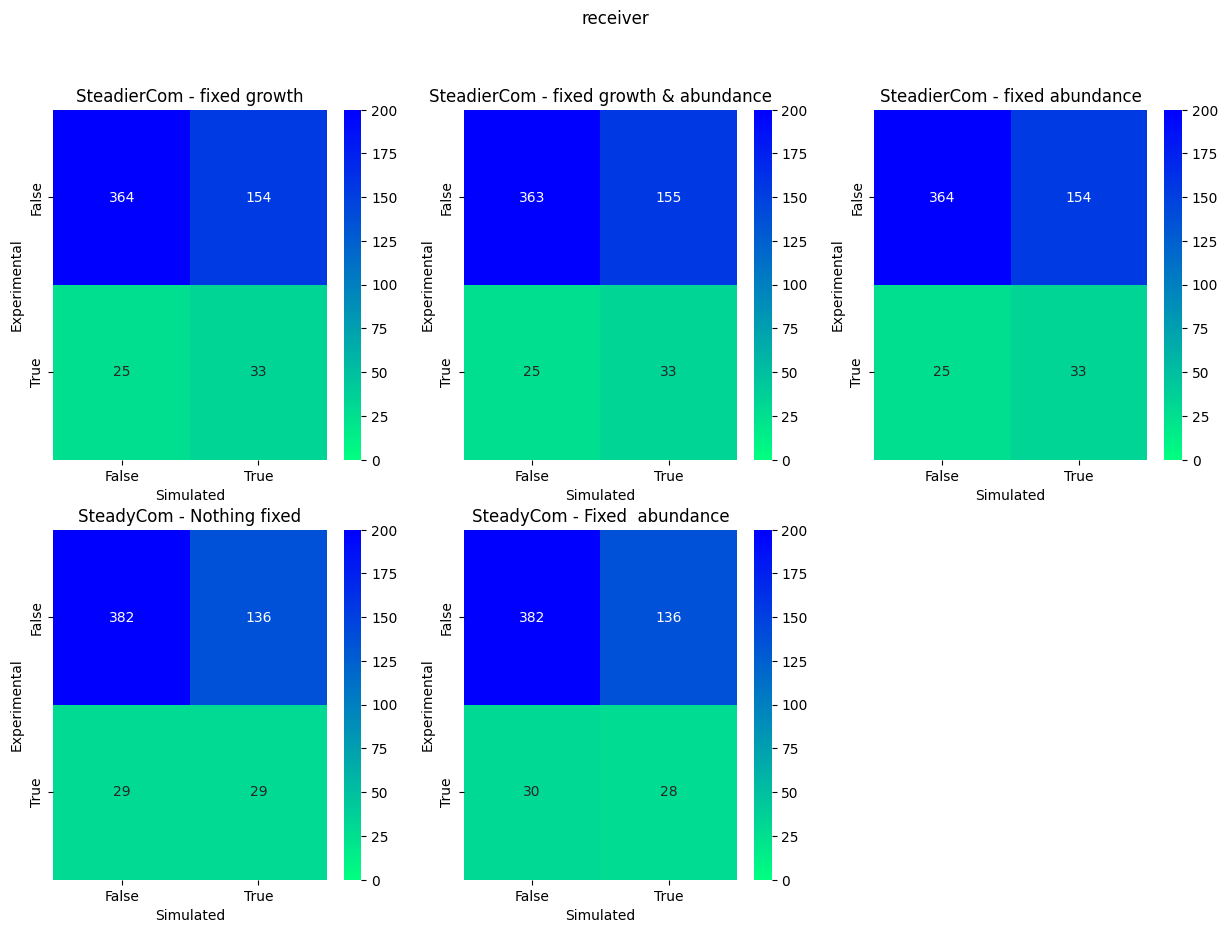

In [26]:
fig,axs = plot_confusion_matrix_venturelli(simulation_dict=simulation_dict,
                                          signal_exp=signal_exp,
                                          receiver_or_donor="receiver",
                                          steadycom_or_smetana="steadycom")


axs[1][-1].set_axis_off()

#### Receiver - SteadierCom and SMETANA - frequency/MUS

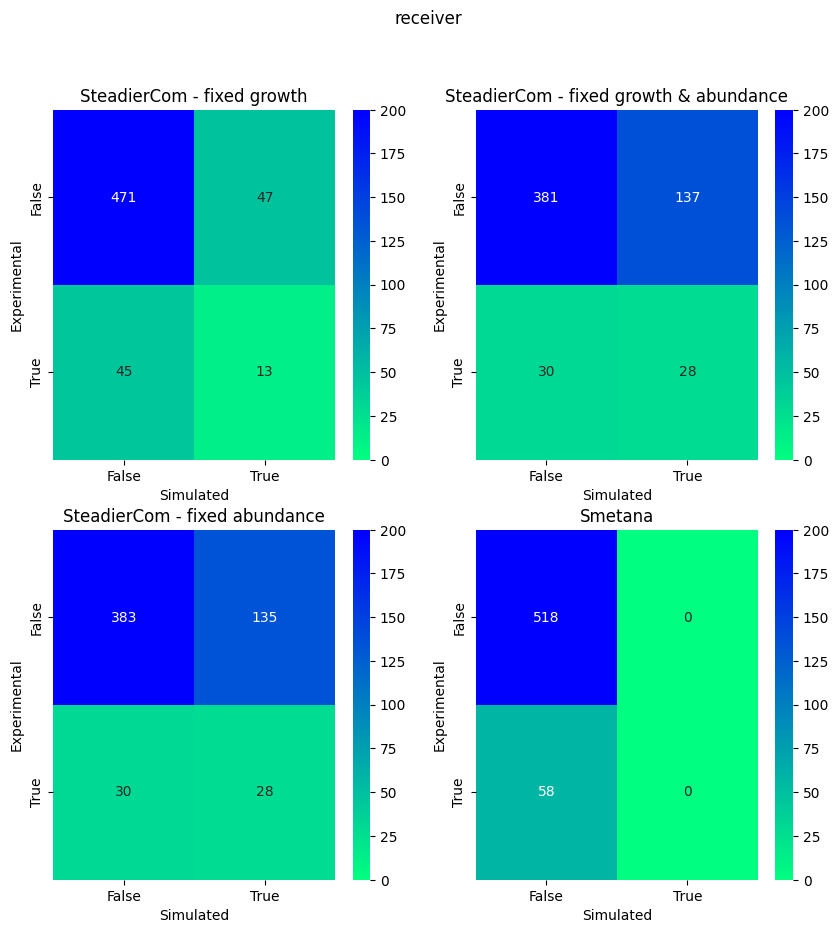

In [27]:
fig,axs = plot_confusion_matrix_venturelli(simulation_dict=simulation_dict,
                                          signal_exp=signal_exp,
                                          receiver_or_donor="receiver",
                                          steadycom_or_smetana="smetana")

#### Donor - SteadierCom and SteadyCom - rate

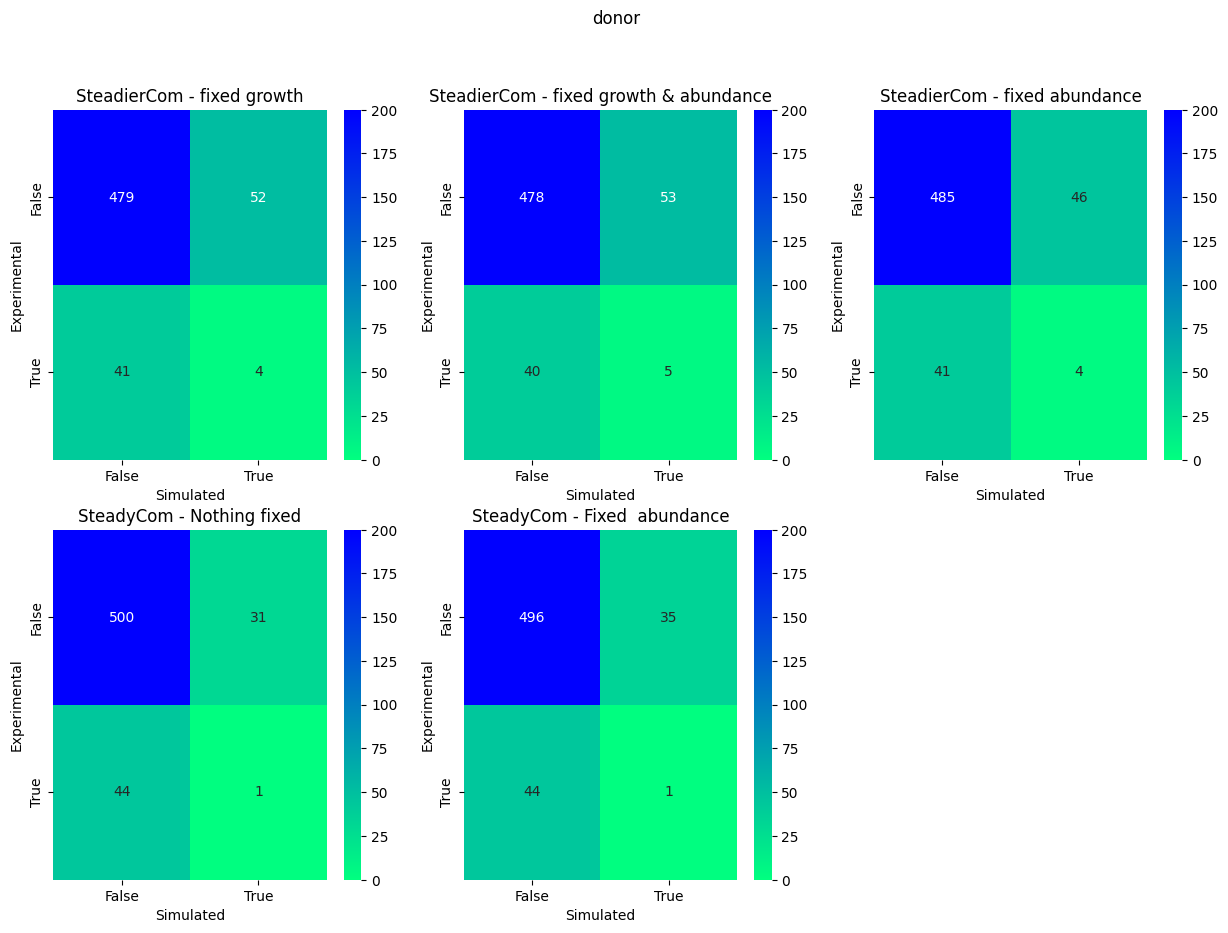

In [28]:
fig,axs = plot_confusion_matrix_venturelli(simulation_dict=simulation_dict,
                                          signal_exp=signal_exp,
                                          receiver_or_donor="donor",
                                          steadycom_or_smetana="steadycom")
axs[1][-1].set_axis_off()

#### Donor - SteadierCom and SMETANA - frequency/MUS

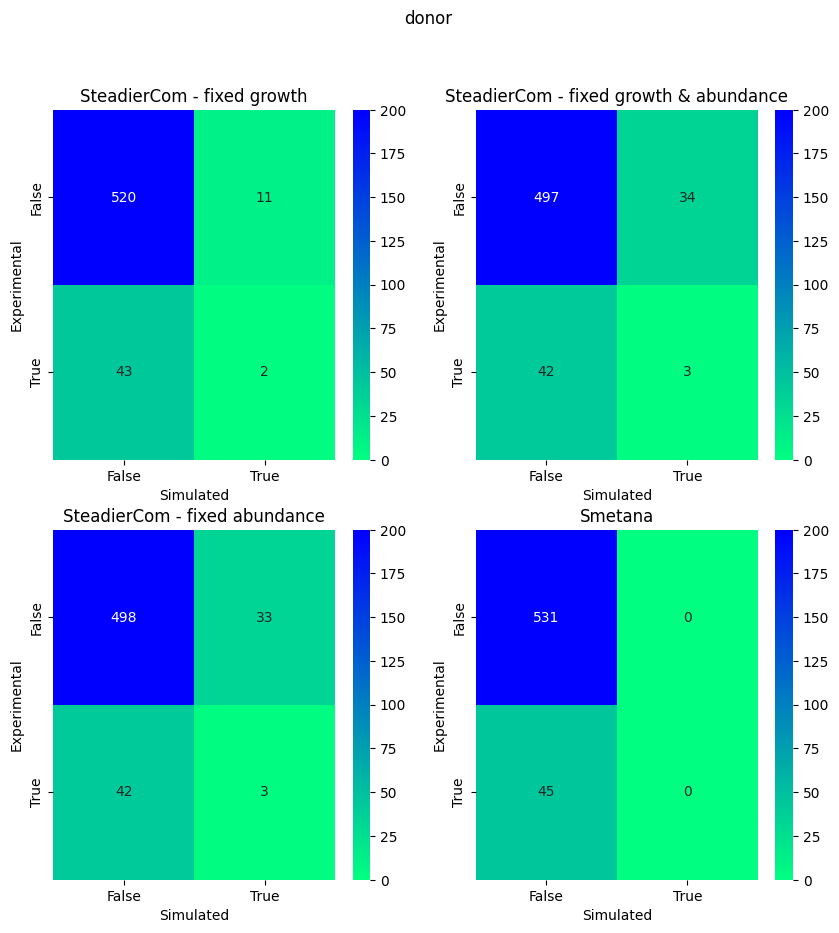

In [29]:
fig,axs = plot_confusion_matrix_venturelli(simulation_dict=simulation_dict,
                                          signal_exp=signal_exp,
                                          receiver_or_donor="donor",
                                          steadycom_or_smetana="smetana")

## Radar charts

In [25]:
simulation_dict["receiver"]["steadiercom"]["SteadierCom - fixed abundance"].rate.median()

np.float64(0.0028868141249521)

In [26]:
simulation_dict["receiver"]["steadycom"]["SteadyCom - Fixed  abundance"]["rate?"].median()

np.float64(0.0342236404260255)

In [27]:
simulation_dict["receiver"]["steadiercom"]["SteadierCom - fixed abundance"].rate.max()

np.float64(4.802907928665595)

In [28]:
simulation_dict["receiver"]["steadycom"]["SteadyCom - Fixed  abundance"]["rate?"].max()

np.float64(43.016592894496775)

In [98]:
### Receivers -  SteadierCom - Radar chart - frequency

receiver_or_donor_list = ["receiver","donor"]

scores_dict = {}

for receiver_or_donor in receiver_or_donor_list:
    if receiver_or_donor=="receiver":
        exp_condition_str = "< -1"
        
        sim_thresh_freq = 0.1
        sim_thresh_rate = 1e-4
    elif receiver_or_donor=="donor":
        exp_condition_str = "> 1"   
        sim_thresh_freq = 0.01
        sim_thresh_rate = 1e-5
    
    scores_dict[receiver_or_donor]={}
    
    

    scores_dict[receiver_or_donor]["steadiercom_frequency"]= scoring_met(simulation_res_dict=simulation_dict[receiver_or_donor]["steadiercom"],
                                                       signal_exp=signal_exp,
                                                       exp_condition_str=exp_condition_str,
                                                       sim_thresh=sim_thresh_freq, 
                                                       agg_method="mean", 
                                                       receiver_or_donor=receiver_or_donor,
                                                       met_column="met_group")

    
    scores_dict[receiver_or_donor]["steadiercom_rate"]=scoring_met(simulation_res_dict = simulation_dict[receiver_or_donor]["steadiercom"],
                                                        signal_exp=signal_exp,
                                                        sim_metric="rate",
                                                        exp_condition_str=exp_condition_str,
                                                        sim_thresh=sim_thresh_rate,
                                                        agg_method="sum", 
                                                        receiver_or_donor=receiver_or_donor,                                       
                                                        met_column="met_group")                        

    scores_dict[receiver_or_donor]["steadycom_rate"]= scoring_met(simulation_res_dict = simulation_dict[receiver_or_donor]["steadycom"],
                                                        signal_exp=signal_exp,
                                                        sim_metric="rate?",
                                                        exp_condition_str=exp_condition_str,
                                                        sim_thresh=sim_thresh_rate,
                                                        agg_method="sum", 
                                                        receiver_or_donor=receiver_or_donor,
                                                        met_column="met_group")
    scores_dict[receiver_or_donor]["smetana"]= scoring_met(simulation_res_dict = simulation_dict[receiver_or_donor]["smetana"],
                                                        signal_exp=signal_exp,
                                                        sim_metric="mus",
                                                        exp_condition_str=exp_condition_str,
                                                        sim_thresh=sim_thresh_rate,
                                                        agg_method="mean", 
                                                        receiver_or_donor=receiver_or_donor,
                                                        met_column="met_group")

/Users/idunmariaburgos/opt/anaconda3/envs/steadiercom/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/idunmariaburgos/opt/anaconda3/envs/steadiercom/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/Users/idunmariaburgos/opt/anaconda3/envs/steadiercom/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this beh

{{receiver_or_donor}}

### Receivers - SteadyCom vs SteadierCom - rate

Text(0.5, 0.98, 'receiver')

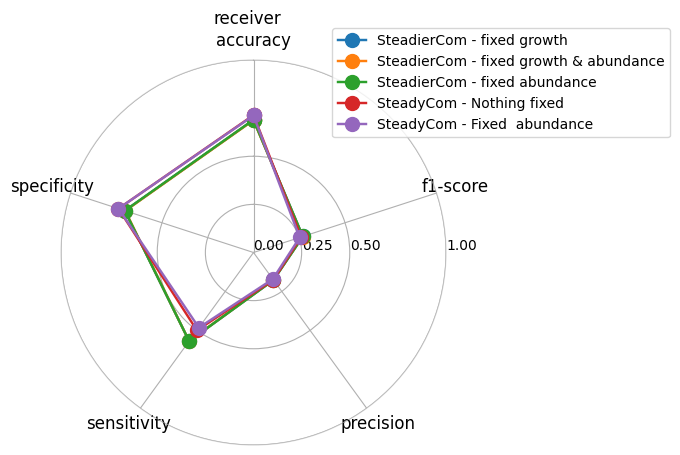

In [99]:
receiver_or_donor ="receiver"
scores_df_all = pd.concat([scores_dict[receiver_or_donor]["steadiercom_rate"],
                           scores_dict[receiver_or_donor]["steadycom_rate"]],axis=1)

fig, ax = plot_radar_chart(scores_df_all)
fig.suptitle(receiver_or_donor)

### Receivers - SteadierCom - frequency

Text(0.5, 0.98, 'receiver')

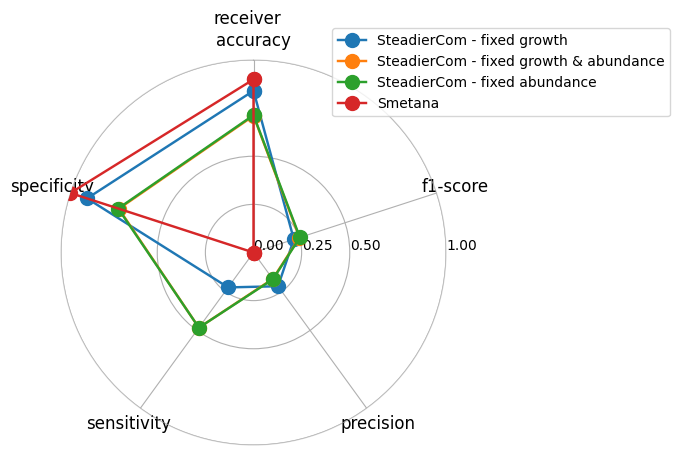

In [300]:
receiver_or_donor ="receiver"
scores_df_all = pd.concat([scores_dict[receiver_or_donor]["steadiercom_frequency"],
                           scores_dict[receiver_or_donor]["smetana"]],axis=1)


fig, ax = plot_radar_chart(scores_df_all)
fig.suptitle(receiver_or_donor)

### Donors - SteadyCom vs SteadierCom - rate

Text(0.5, 0.98, 'donor')

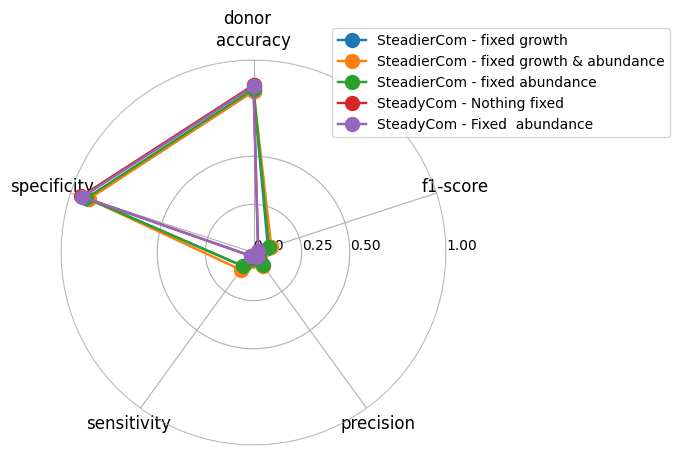

In [301]:
receiver_or_donor = "donor"
scores_df_all = pd.concat([scores_dict[receiver_or_donor]["steadiercom_rate"],
                           scores_dict[receiver_or_donor]["steadycom_rate"]],axis=1)

fig, ax = plot_radar_chart(scores_df_all)
fig.suptitle(receiver_or_donor)

### Donors - SteadierCom - frequency

Text(0.5, 0.98, 'donor')

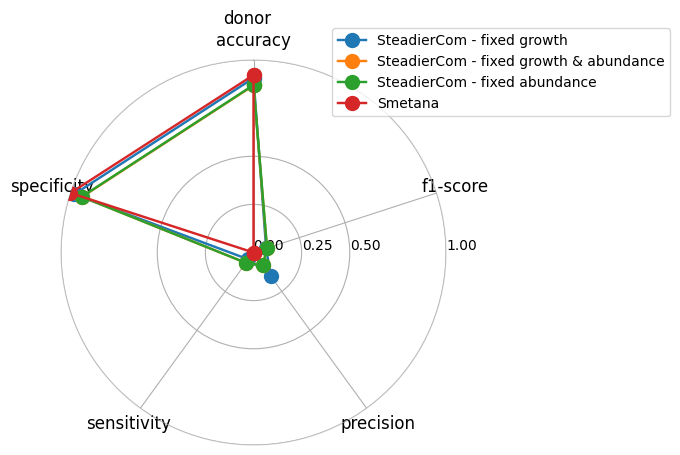

In [102]:
receiver_or_donor ="donor"
scores_df_all = pd.concat([scores_dict[receiver_or_donor]["steadiercom_frequency"],
                           scores_dict[receiver_or_donor]["smetana"]],axis=1)


fig, ax = plot_radar_chart(scores_df_all)
fig.suptitle(receiver_or_donor)